# Step 1: Data Audit & Exploratory Data Analysis
**Project:** Student Mental Health Risk Prediction
**Goal:** Understand the structure, quality, and relationships in the dataset before modeling.

**Tasks:**
1. Load data & check structure.
2. Audit missing values, duplicates, and anomalies.
3. Analyze target distribution (Low / Medium / High).
4. Explore relationships between features and the target.
5. Check for potential target leakage.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set styling for plots
sns.set_theme(style="whitegrid")

# Load dataset
df = pd.read_csv('../data/raw/student_mental_health.csv')

print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")
display(df.head())

Dataset Shape: 2000 rows, 17 columns


,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
0,STU0001,22,Male,3,6.6,17.6,2.91,6.9,7.5,Moderate,8.5,4.0,78.0,No,Poor,No,High
1,STU0002,21,Male,4,5.6,22.4,2.92,7.6,11.5,Low,4.5,5.3,85.4,Yes,Average,No,Medium
2,STU0003,22,Male,5,7.1,28.1,2.68,6.5,8.9,Low,4.8,6.1,79.5,No,Average,No,Medium
3,STU0004,24,Male,1,4.5,14.8,2.23,5.5,7.6,High,3.7,8.0,73.9,No,Average,Yes,High
4,STU0005,20,Female,1,6.7,17.2,2.69,4.3,7.0,Moderate,8.0,7.4,99.8,Yes,NaN,No,Medium


## 1. Data Structure & Types
Check the data types and identify the target variable.

In [4]:
# Data types and non-null counts
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Student_ID                      2000 non-null   str    
 1   Age                             2000 non-null   int64  
 2   Gender                          2000 non-null   str    
 3   Year_of_Study                   2000 non-null   int64  
 4   Sleep_Hours                     1938 non-null   float64
 5   Study_Hours_Per_Week            2000 non-null   float64
 6   GPA                             1962 non-null   float64
 7   Social_Media_Hours              1942 non-null   float64
 8   Screen_Time_Hours               2000 non-null   float64
 9   Physical_Activity               2000 non-null   str    
 10  Financial_Stress                1909 non-null   float64
 11  Family_Support                  1946 non-null   float64
 12  Attendance_Rate                 1953 non-null

## 2. Missing Values Audit
**Observation:** Which columns have missing data?
**Decision:** How will we impute them in the pipeline? (Numeric -> Median, Categorical -> Mode or Missing Category).

In [5]:
missing = df.isnull().sum()
missing_pct = (missing / len(df)) * 100
missing_df = pd.DataFrame({'Missing Count': missing, 'Percentage (%)': missing_pct})
display(missing_df[missing_df['Missing Count'] > 0].sort_values(by='Percentage (%)', ascending=False))

,Missing Count,Percentage (%)
Financial_Stress,91,4.55
Diet_Quality,69,3.45
Sleep_Hours,62,3.10
Social_Media_Hours,58,2.90
Family_Support,54,2.70
Attendance_Rate,47,2.35
GPA,38,1.90


## 3. Impossible Values & Outliers
**Observation:** Are there values that violate the data dictionary? (e.g., Sleep > 24 hours, GPA > 4.0, Attendance > 100%). 
**Decision:** We will cap outliers using IQR inside the pipeline.

In [6]:
# Check min and max for numerical columns
display(df.describe().loc[['min', 'max']])

# Check for duplicates
print(f"Number of duplicate rows: {df.duplicated().sum()}")

,Age,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Financial_Stress,Family_Support,Attendance_Rate
min,17.0,1.0,3.3,2.4,1.50,2.1,3.3,1.4,1.7,54.4
max,29.0,5.0,10.0,38.3,3.66,10.0,14.0,10.0,9.9,100.0


Number of duplicate rows: 0


## 4. Target Distribution (Class Balance)
**Observation:** Is the dataset balanced? 
**Decision:** If imbalanced, we use SMOTE or `class_weight='balanced'`. If balanced, we still use `class_weight` to ensure the model doesn't ignore the minority class.

C:\Users\ycode\AppData\Local\Temp\ipykernel_28152\2797855491.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Mental_Health_Risk', order=['Low', 'Medium', 'High'], palette='viridis')


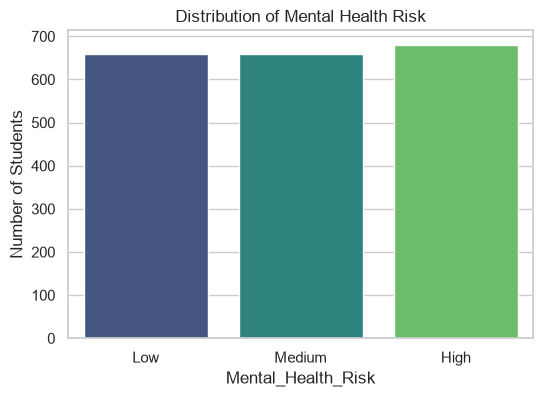

Mental_Health_Risk
High      34.0
Medium    33.0
Low       33.0
Name: proportion, dtype: float64


In [7]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Mental_Health_Risk', order=['Low', 'Medium', 'High'], palette='viridis')
plt.title('Distribution of Mental Health Risk')
plt.ylabel('Number of Students')
plt.show()

print(df['Mental_Health_Risk'].value_counts(normalize=True) * 100)

## 5. Critical Check: Target Leakage
**Observation:** Does `Previous_Mental_Health_History` perfectly predict the target? If "Yes" always equals "High Risk", it's a leak. 
**Result:** Based on the crosstab, it is a strong predictor but not a perfect leak.

In [8]:
crosstab = pd.crosstab(df['Previous_Mental_Health_History'], df['Mental_Health_Risk'], normalize='index') * 100
display(crosstab.round(2))

Mental_Health_Risk,High,Low,Medium
Previous_Mental_Health_History,,,
No,27.41,39.28,33.31
Yes,49.66,18.07,32.26


## 6. Bivariate Analysis (Features vs Target)
**Observation:** How do key numeric features (Sleep, GPA, Financial Stress) vary across the risk levels?

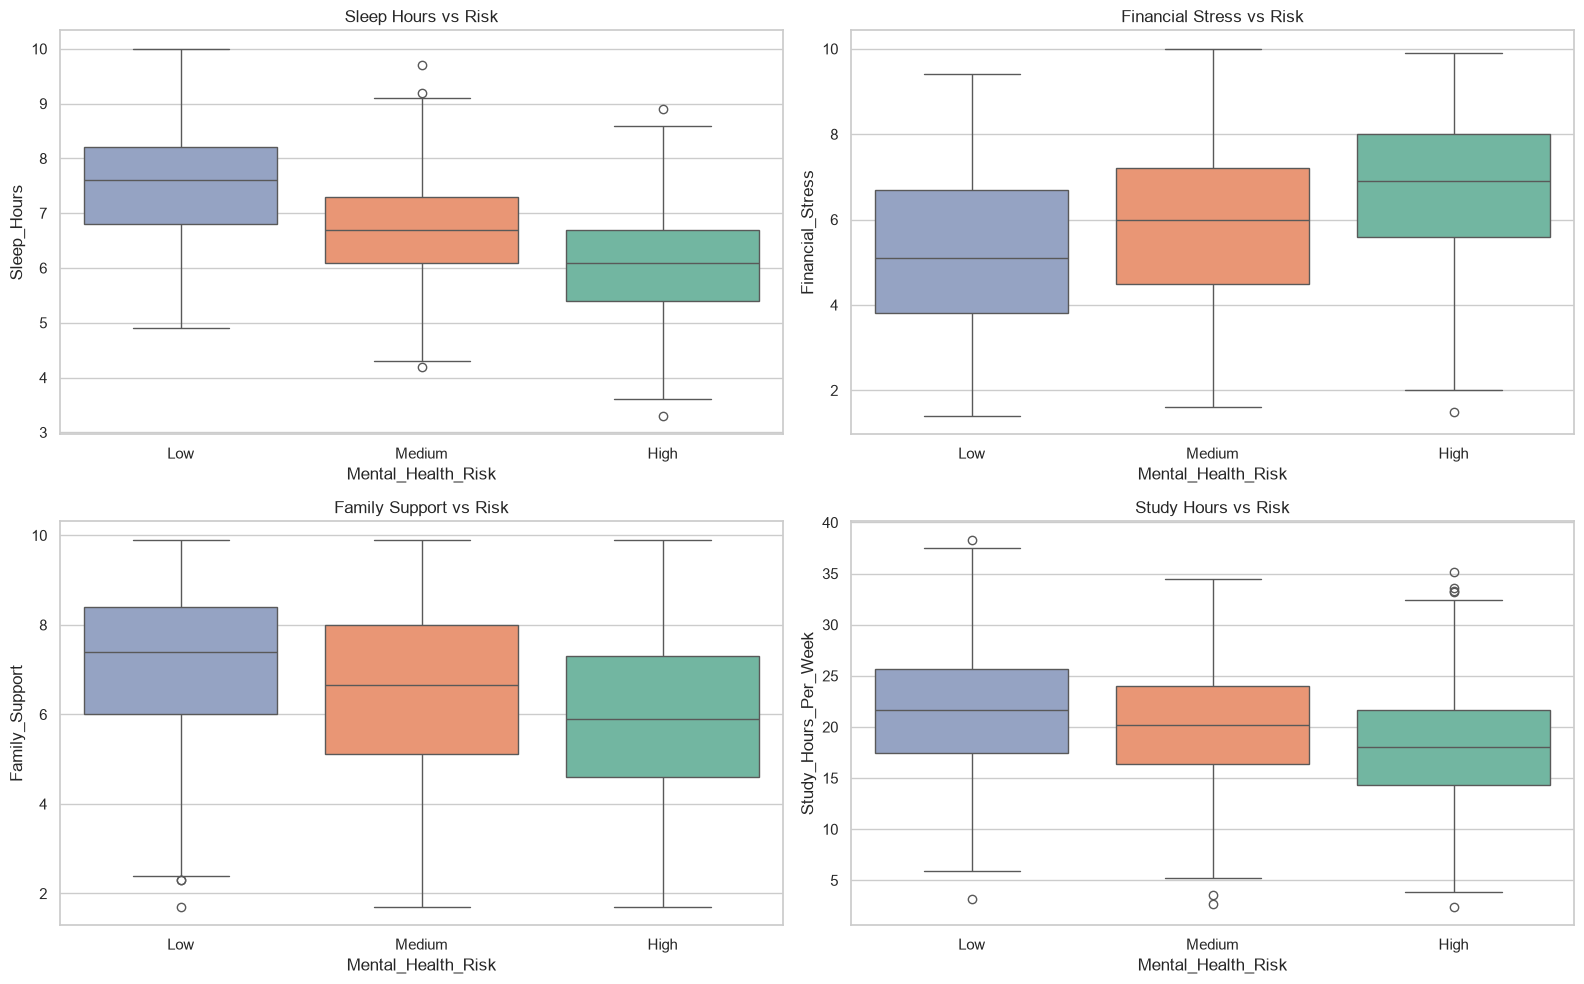

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Adding hue and legend=False fixes the warning
sns.boxplot(data=df, x='Mental_Health_Risk', y='Sleep_Hours', order=['Low', 'Medium', 'High'], hue='Mental_Health_Risk', palette='Set2', legend=False, ax=axes[0,0])
axes[0,0].set_title('Sleep Hours vs Risk')

sns.boxplot(data=df, x='Mental_Health_Risk', y='Financial_Stress', order=['Low', 'Medium', 'High'], hue='Mental_Health_Risk', palette='Set2', legend=False, ax=axes[0,1])
axes[0,1].set_title('Financial Stress vs Risk')

sns.boxplot(data=df, x='Mental_Health_Risk', y='Family_Support', order=['Low', 'Medium', 'High'], hue='Mental_Health_Risk', palette='Set2', legend=False, ax=axes[1,0])
axes[1,0].set_title('Family Support vs Risk')

sns.boxplot(data=df, x='Mental_Health_Risk', y='Study_Hours_Per_Week', order=['Low', 'Medium', 'High'], hue='Mental_Health_Risk', palette='Set2', legend=False, ax=axes[1,1])
axes[1,1].set_title('Study Hours vs Risk')

plt.tight_layout()
plt.show()

## 7. Correlation Heatmap
**Observation:** Which features are highly correlated with each other? (Multicollinearity check). 
**Note:** We use Spearman correlation because survey data is often non-linear and ordinal.

<Figure size 1400x1000 with 0 Axes>

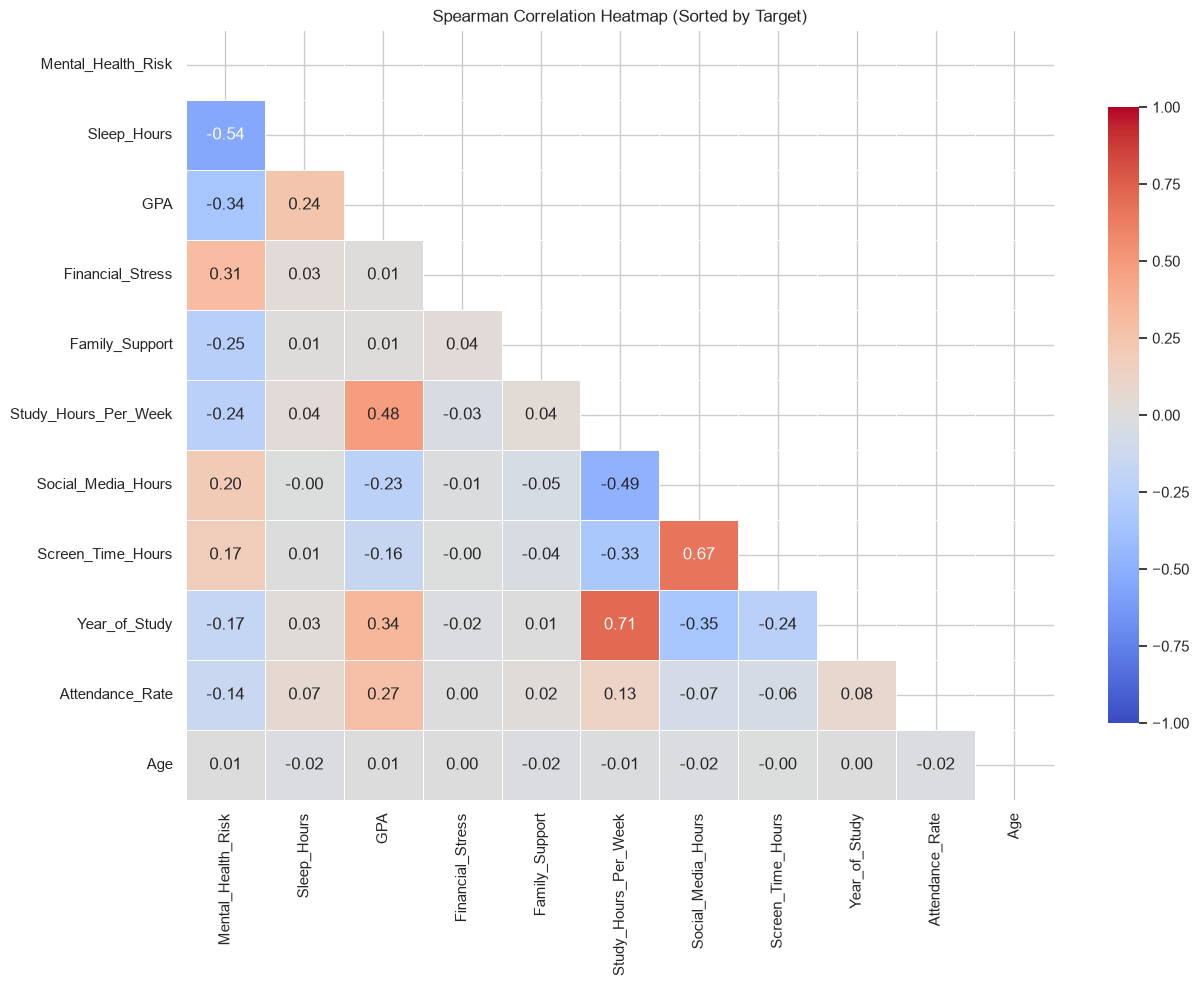

In [17]:
plt.figure(figsize=(14, 10))

# 1. Prepare data (copy, drop ID, map target)
df_corr = df.copy()
if 'Student_ID' in df_corr.columns:
    df_corr = df_corr.drop(columns=['Student_ID'])
    
risk_map = {'Low': 0, 'Medium': 1, 'High': 2}
df_corr['Mental_Health_Risk'] = df_corr['Mental_Health_Risk'].map(risk_map)
numeric_df = df_corr.select_dtypes(include=[np.number])

# 2. Calculate correlation
corr_matrix = numeric_df.corr(method='spearman')

# 3. Sort features by their correlation with the Target
target_corr = corr_matrix[['Mental_Health_Risk']]
sorted_features = target_corr.abs().sort_values(by='Mental_Health_Risk', ascending=False).index
corr_matrix = corr_matrix.loc[sorted_features, sorted_features]

# 4. Mask the upper triangle
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

# 5. Plot
plt.figure(figsize=(14, 10))
sns.heatmap(corr_matrix, 
            mask=mask, 
            annot=True, 
            cmap='coolwarm', 
            fmt=".2f", 
            vmin=-1, vmax=1, # Lock scale to -1 to +1
            linewidths=0.5, 
            cbar_kws={"shrink": .8})

plt.title("Spearman Correlation Heatmap (Sorted by Target)")
plt.show()

## EDA Summary & Decisions
1. **Data quality:** The dataset contains 2,000 rows and 17 columns, with no duplicate rows. Numeric ranges are plausible: age 17–29, GPA 1.50–3.66, sleep 3.3–10.0 hours, and attendance 54.4–100.0%.
2. **Missing values:** Missing data occurs in `Financial_Stress` (91; 4.55%), `Diet_Quality` (69; 3.45%), `Sleep_Hours` (62; 3.10%), `Social_Media_Hours` (58; 2.90%), `Family_Support` (54; 2.70%), `Attendance_Rate` (47; 2.35%), and `GPA` (38; 1.90%). The modeling pipeline will impute numeric features with the median and categorical features with the most frequent value.
3. **Class balance:** The target contains 660 Low (33.0%), 660 Medium (33.0%), and 680 High (34.0%) cases, so the classes are sufficiently balanced and SMOTE is not required. Stratified splitting will preserve this distribution; `class_weight='balanced'` may still be compared during model selection.
4. **Key predictors:** Spearman correlations with the ordinal target identify `Sleep_Hours` (-0.54), `GPA` (-0.34), and `Financial_Stress` (0.31) as the strongest numeric associations. The boxplots also show lower sleep and family support, and higher financial stress, among higher-risk students.
5. **Leakage:** `Previous_Mental_Health_History` is a strong predictor but not a perfect leak: students with a history are 49.66% High risk, while those without one are 27.41% High risk. It will be retained as a feature.